# Imports

In [2]:
import zipfile

from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import geopandas as gpd
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

plt.style.use('pgf.mplstyle')
plt.rcParams['font.family'] = 'serif'
jax.config.update("jax_enable_x64", True)

# Unzip Data

In [3]:
# unzip ../data/trip_count/trip_count_matrix_county_by_age_activity_final_2024.zip to csv file
with zipfile.ZipFile("../data/trip_count/trip_count_matrix_county_by_age_activity_final_2024.zip", 'r') as zip_ref:
    zip_ref.extractall("../data/trip_count/")

In [4]:
with zipfile.ZipFile("../data/vg250/DE_VG250.zip", 'r') as zip_ref:
    zip_ref.extractall("../data/vg250/")

# Load Data

In [5]:
# load the data
df_trips = pl.read_csv("../data/trip_count/trip_count_matrix_county_by_age_activity_final_2024.csv")
df_trips = df_trips.group_by(["start_county", "end_county"]).agg(pl.sum("trip_cnt").alias("trip_cnt"))

In [6]:
df_population = pl.read_csv("../data/population/12411-0016_de.csv", separator=";", skip_rows=5)
df_population = df_population.select([pl.col("_duplicated_0").alias("county"),
                                     pl.col("_duplicated_1").alias("county_name"),
                                     pl.col("Insgesamt").alias("population")])
df_population = df_population.drop_nulls()
df_population = df_population.filter(pl.col("population") != "-")
df_population = df_population.with_columns(pl.col("population").cast(pl.Int64))
df_population = df_population.sort("county")

In [7]:
# sorted list of counties
start_counties = sorted(df_trips["start_county"].unique())
end_counties = sorted(df_trips["end_county"].unique())
assert start_counties == end_counties, "Start and end counties do not match"
# create map county id -> index
county_to_index = {county: i for i, county in enumerate(start_counties)}

W = np.zeros((len(start_counties), len(end_counties)))
for row in df_trips.iter_rows():
    start_county, end_county, trip_cnt = row
    if start_county == end_county:
        continue
    i = county_to_index[start_county]
    j = county_to_index[end_county]
    start_county_population = df_population[i]["population"][0]
    end_county_population = df_population[j]["population"][0]
    W[j, i] += 0.5 * trip_cnt / start_county_population
    W[i, j] += 0.5 * trip_cnt / end_county_population

In [8]:
gdf = gpd.read_file("../data/vg250/DE_VG250.gpkg", layer="vg250_krs")
gdf = gdf.iloc[:401]
gdf = gdf[gdf["AGS"].astype(int).isin([int(c) for c in start_counties])]

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

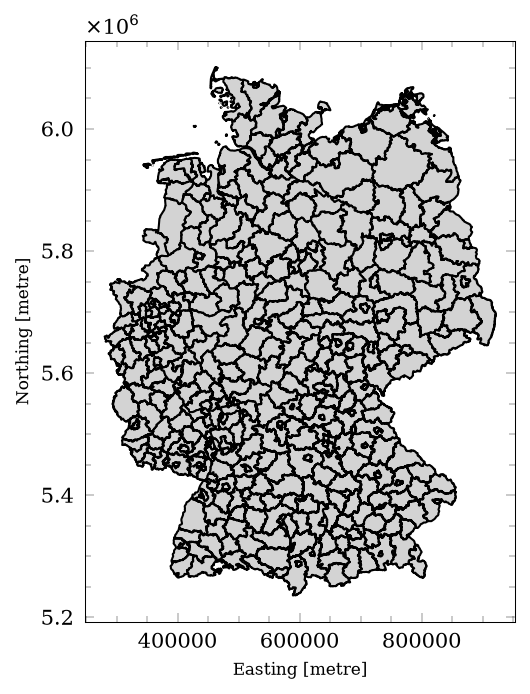

In [9]:
fig, ax = plt.subplots(figsize=(5, 5), dpi=150)
gdf.plot(ax=ax, color='lightgray', edgecolor='black')

# Class/Function Definitions

In [10]:
N_VARS = 3  # S, I, R

In [11]:
class Parameters:
    def __init__(self, *, alpha: float, beta: float, gamma: float, quarantine_factor: float) -> None:
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.n_cities = W.shape[0]
        self.W =  np.array((1 - quarantine_factor) *  W)
        self.W_colsum = jnp.sum(self.W, axis=0)

In [12]:
@jax.jit(static_argnames=("p",))
def f(t, y: jnp.ndarray, p: Parameters):
    S, I, R = y.reshape((N_VARS, -1))

    N = S + I + R
    recovery_rate = p.alpha * I
    infection_rate = p.beta * S * I / N
    vaccination_rate = p.gamma * S

    dS = -infection_rate - vaccination_rate + p.W @ S - p.W_colsum * S
    dI = infection_rate - recovery_rate + p.W @ I - p.W_colsum * I
    dR = vaccination_rate + recovery_rate + p.W @ R - p.W_colsum * R

    return jnp.concat((dS, dI, dR))

In [13]:
def make_initial_condition(*,
                           initial_county: int | None = None,
                           initial_vaccination_rate: float = 0.0,
                           random_seed: int | None = None) -> np.ndarray:
    rng = np.random.default_rng(random_seed)

    if initial_county is not None:
        initial_infected_county = county_to_index[initial_county]
    else:
        initial_infected_county = rng.choice(len(start_counties))

    S0 = df_population["population"].to_numpy().astype(float)
    I0 = np.zeros_like(S0)
    I0[initial_infected_county] = 1.0
    R0 = initial_vaccination_rate * S0
    S0 -= I0 + R0
    return np.concatenate((S0, I0, R0))

In [15]:
# R0 = 12-18
# contagious period ~ 8 days
p = Parameters(alpha=1/8, beta=15/8, gamma=1 - 0.2**(1/365), quarantine_factor=0.9)
term = ODETerm(f)
solver = Tsit5()

In [16]:
y0 = make_initial_condition()

In [17]:
t0 = 0.0
t1 = 100.0
dt0 = 1.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0))

In [18]:
solution = diffeqsolve(term, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)

In [19]:
ts = solution.ts
ys = solution.ys.reshape((-1, N_VARS, p.n_cities)) # type: ignore

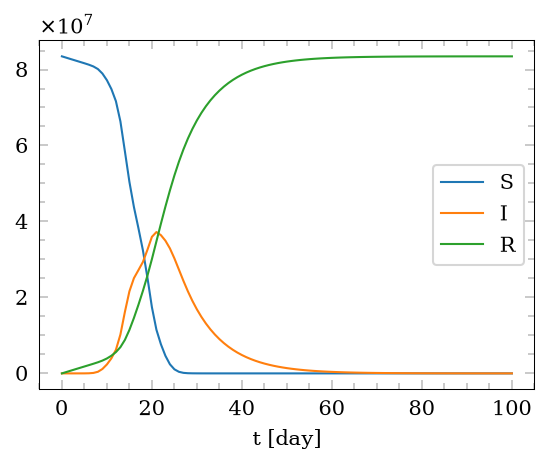

In [20]:
# plot S, I, R reduced over counties
plt.figure(figsize=(4, 3), dpi=150)
S_reduced = jnp.sum(ys[:, 0, :], axis=1)
I_reduced = jnp.sum(ys[:, 1, :], axis=1)
R_reduced = jnp.sum(ys[:, 2, :], axis=1)
plt.plot(ts, S_reduced, label="S")
plt.plot(ts, I_reduced, label="I")
plt.plot(ts, R_reduced, label="R")
plt.xlabel("t [day]")
plt.legend()

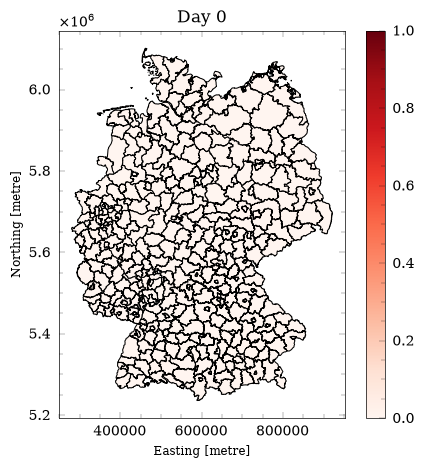

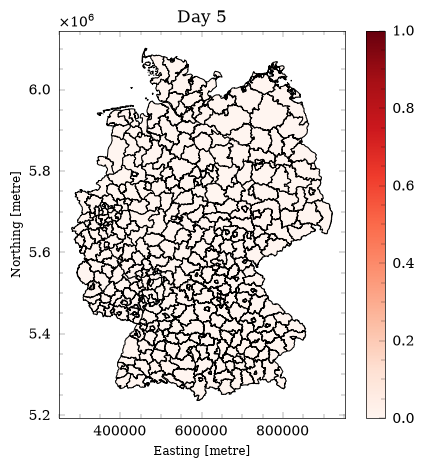

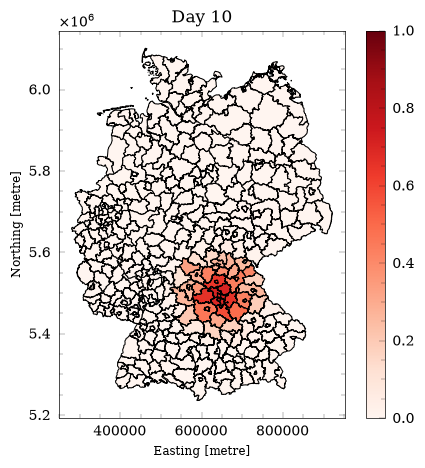

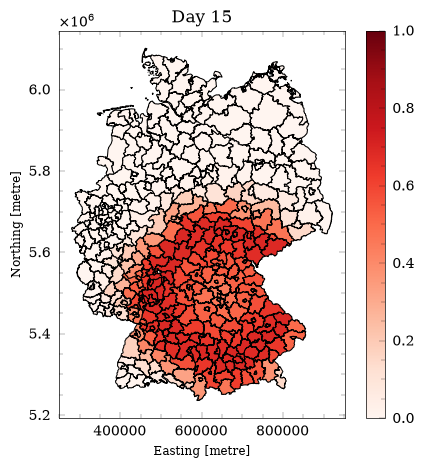

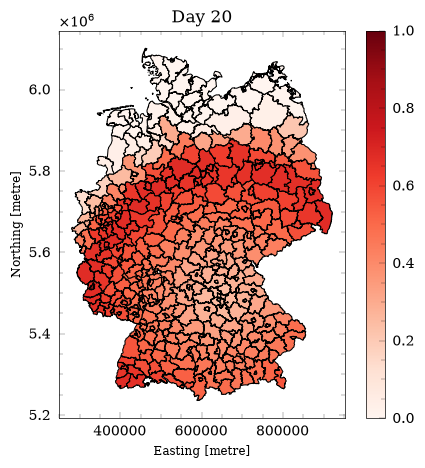

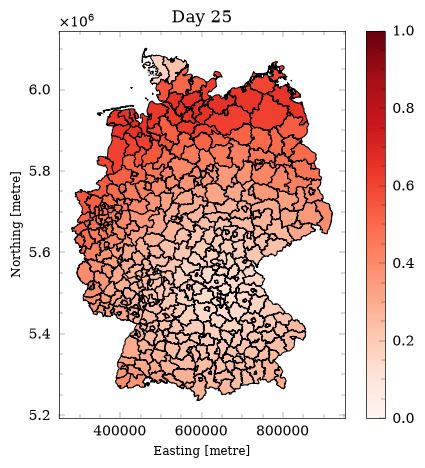

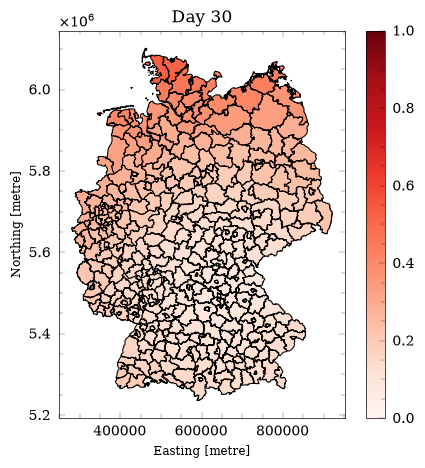

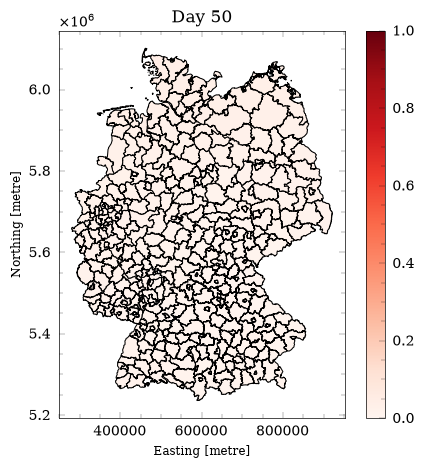

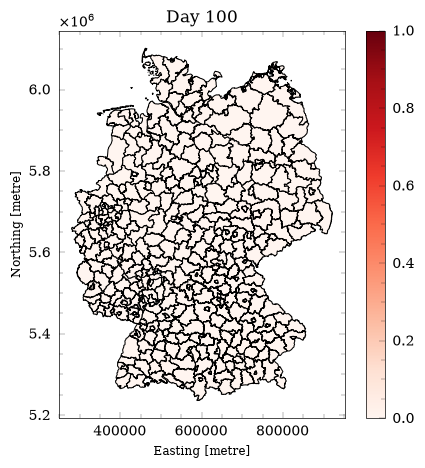

In [21]:
# plot map of infected individuals day 0, 50, 100, ..., 300
for day in [0, 5, 10, 15, 20, 25, 30, 50, 100]:
    plt.figure(figsize=(5,5))
    plt.title(f"Day {day}")
    S, I, R = ys[day, :, :]
    gdf['infected'] = I / (S + I + R)
    gdf.plot(column='infected', ax=plt.gca(), legend=True, cmap='Reds', edgecolor='black', linewidth=0.75, vmin=0, vmax=1)
    plt.show()